In [1]:
import torch
import matplotlib.pyplot as plt

from flowmodels.score import ScoreNetwork, score_matching_loss

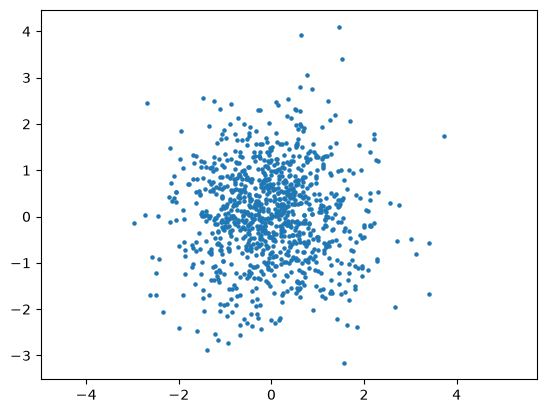

In [2]:
torch.manual_seed(0)

x = torch.randn(1000, 2)

plt.scatter(x[:, 0], x[:, 1], s=5)
plt.axis("equal")
plt.show()

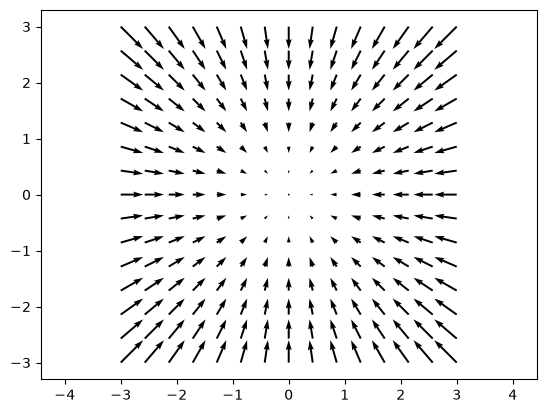

In [3]:
grid = torch.linspace(-3, 3, 15)
xx, yy = torch.meshgrid(grid, grid, indexing="ij")

points = torch.stack([xx.flatten(), yy.flatten()], dim=1)

true_score = -points

plt.quiver(
    points[:, 0],
    points[:, 1],
    true_score[:, 0],
    true_score[:, 1],
)
plt.axis("equal")
plt.show()

In [4]:
model = ScoreNetwork()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []

for step in range(2000):
    x = torch.randn(256, 2)

    loss = score_matching_loss(model, x)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 200 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

step    0 | loss 0.0253
step  200 | loss -0.9364
step  400 | loss -1.0588
step  600 | loss -0.9947
step  800 | loss -1.0576
step 1000 | loss -1.0225
step 1200 | loss -1.0129
step 1400 | loss -0.9776
step 1600 | loss -1.0831
step 1800 | loss -1.0076


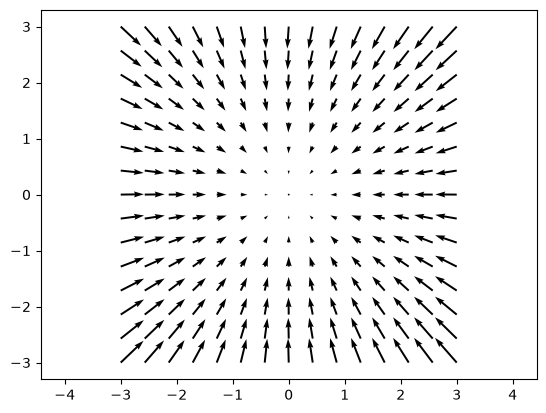

In [5]:
with torch.no_grad():
    learned_score = model(points)

plt.quiver(
    points[:, 0],
    points[:, 1],
    learned_score[:, 0],
    learned_score[:, 1],
)
plt.axis("equal")
plt.show()

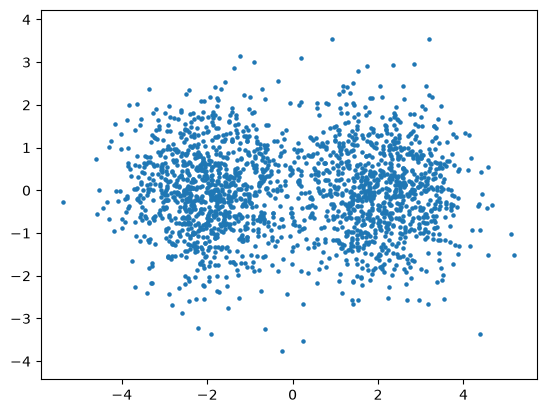

In [6]:
n = 2000

component = torch.randint(0, 2, (n,))
means = torch.tensor([
    [-2.0, 0.0],
    [ 2.0, 0.0],
])

x = torch.randn(n, 2) + means[component]

plt.scatter(x[:, 0], x[:, 1], s=5)
plt.axis("equal")
plt.show()

In [7]:
model = ScoreNetwork()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

losses = []

for step in range(3000):
    component = torch.randint(0, 2, (256,))
    x = torch.randn(256, 2) + means[component]

    loss = score_matching_loss(model, x)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 300 == 0:
        print(f"step {step:4d} | loss {loss.item():.4f}")

step    0 | loss 0.1270
step  300 | loss -0.7809
step  600 | loss -0.9281
step  900 | loss -0.8545
step 1200 | loss -0.8859
step 1500 | loss -0.5933
step 1800 | loss -0.7687
step 2100 | loss -0.8123
step 2400 | loss -0.8940
step 2700 | loss -0.7754


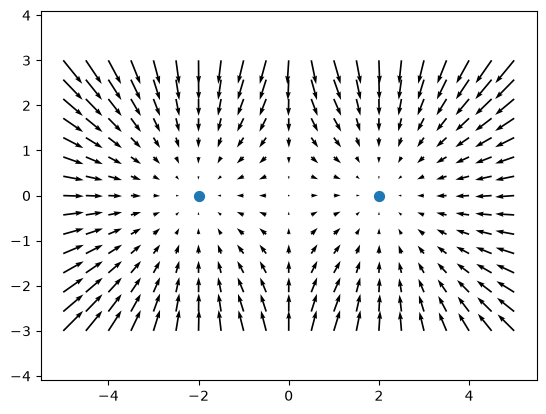

In [8]:
grid_x = torch.linspace(-5, 5, 21)
grid_y = torch.linspace(-3, 3, 15)

xx, yy = torch.meshgrid(grid_x, grid_y, indexing="ij")
points = torch.stack([xx.flatten(), yy.flatten()], dim=1)

with torch.no_grad():
    learned_score = model(points)

plt.quiver(
    points[:, 0],
    points[:, 1],
    learned_score[:, 0],
    learned_score[:, 1],
)
plt.scatter(
    means[:, 0],
    means[:, 1],
    s=50,
)
plt.axis("equal")
plt.show()